In [29]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sko.PSO import PSO

In [19]:
df = pd.read_csv('./dataset/GlobalTemperatures.csv')
df['year'] = df['dt'].str.split('-').str[0].astype(int)
df = df.query("year >= 1800")
# df = df.set_index('dt')

In [20]:
# plt.plot(df.index, df['LandAverageTemperature'])

In [21]:
def create_lags(df, k, value_col):
    """
    Transforma a série temporal em um DataFrame supervisionado.

    k: quantidade de lags
    value_col: nome da coluna com os valores numéricos
    """

    data = df[value_col].copy()

    result = pd.DataFrame()

    for i in range(k, 0, -1):
        result[f'x-{i}'] = data.shift(i)

    result['x'] = data

    result = result.dropna().reset_index(drop=True)

    return result

In [22]:
def predict_ts(k, n, value, plot=False):
    # Transformação supervisionada
    data = create_lags(df, k, value)

    X = data.drop(columns=['x']).values
    y = data['x'].values

    dates = df['dt'].iloc[k:].reset_index(drop=True)

    # Divisão cronológica
    split = int(len(X) * (1 - 0.2))

    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    dates_test = dates.iloc[split:]

    # Normalização
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train = scaler_X.fit_transform(X_train)
    X_test = scaler_X.transform(X_test)

    y_train = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

    # Arquitetura da MLP
    model = MLPRegressor(
        hidden_layer_sizes=(n,),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42,
        early_stopping=True,
        n_iter_no_change=30
    )

    # Treinamento
    model.fit(X_train, y_train)

    # Previsão
    predictions = model.predict(X_test)

    # Retorna à escala original
    predictions = scaler_y.inverse_transform(predictions.reshape(-1, 1)).ravel()

    if plot:
        plt.figure(figsize=(14, 5))

        plt.plot(
            dates_test,
            y_test,
            label='Valores verdadeiros',
            linewidth=1.5
        )

        plt.plot(
            dates_test,
            predictions,
            label='Valores preditos',
            linewidth=1.5,
            linestyle='--'
        )

        # plt.xlabel('Data')
        # plt.ylabel('Temperatura média (°C)')
        # plt.title(f'Previsão da série temporal (k={k}, n={n})')

        # plt.legend()
        # plt.grid(alpha=0.3)
        # plt.xticks(rotation=45)
        # plt.tight_layout()
        # plt.show()
            

    return y_test, predictions

In [ ]:
# def plot_ts(true, pred):
#     plt.figure(figsize=(14, 5))
    
#     plt.plot(
#         dates_test,
#         y_test,
#         label='Valores verdadeiros',
#         linewidth=1.5
#     )

#     plt.plot(
#         dates_test,
#         predictions,
#         label='Valores preditos',
#         linewidth=1.5,
#         linestyle='--'
#     )

In [30]:
def fitness(params):
    k = int(round(params[0]))
    n = int(round(params[1]))

    y_test, predictions = predict_ts(k, n, 'LandAverageTemperature')

    # Erro de validação
    mse = root_mean_squared_error(y_test, predictions)

    return mse

In [31]:
fitness([10, 42])

0.3781558669727591

(array([ 3.778,  3.038,  3.898,  5.82 ,  8.938, 11.769, 13.824, 14.435,
        13.869, 12.125,  9.609,  6.222,  3.832,  2.261,  2.582,  5.19 ,
         8.386, 11.198, 13.382, 14.288, 14.016, 11.744,  9.098,  5.915,
         3.55 ,  3.059,  3.395,  5.706,  8.584, 11.742, 13.557, 14.351,
        13.514, 12.152,  9.318,  5.893,  3.667,  2.884,  3.031,  4.517,
         8.294, 10.942, 13.086, 14.155, 13.511, 11.895,  8.511,  5.66 ,
         3.681,  2.492,  3.471,  5.702,  8.85 , 11.78 , 13.876, 14.631,
        14.09 , 11.862,  9.156,  6.544,  3.749,  2.705,  3.456,  5.607,
         8.791, 11.414, 13.22 , 14.364, 13.297, 12.03 ,  9.339,  6.35 ,
         3.74 ,  2.679,  2.841,  5.474,  8.455, 11.199, 13.487, 14.114,
        13.833, 12.247,  9.586,  6.286,  4.6  ,  2.956,  3.652,  5.367,
         8.935, 11.77 , 13.582, 14.742, 14.189, 12.321,  9.55 ,  6.684,
         4.016,  3.785,  4.021,  6.239,  8.953, 11.565, 13.765, 14.738,
        14.502, 12.236,  9.394,  6.273,  4.519,  2.558,  3.281, 

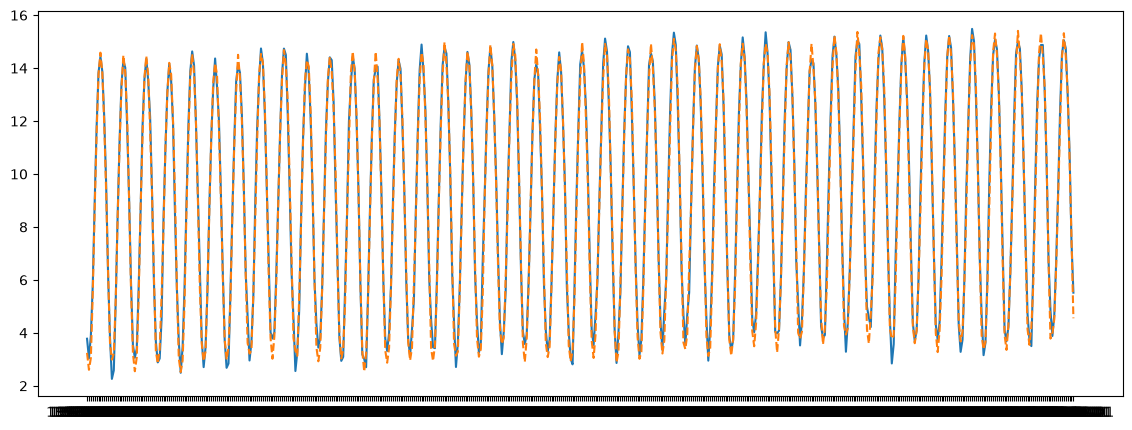

In [27]:
predict_ts(10, 42, 'LandAverageTemperature', True)

In [25]:
# pso = PSO(func=fitness, n_dim=2, pop=10, max_iter=150, lb=[3, 10], ub=[10, 50], w=0.8, c1=0.5, c2=0.5)
# pso.run()